
# 🎬 Movie Recommendation System

The Movie Recommendation System is a machine learning project designed to recommend movies to users based on their interests and previous rating patterns. This project uses the MovieLens dataset, which contains movie details, user ratings, genres, and tags.

The system combines **Content-Based Filtering** and **Item-Based Collaborative Filtering** to generate personalized movie recommendations. TF-IDF Vectorization and Cosine Similarity are used to identify similar movies, while user rating patterns help predict movie preferences.

A Hybrid Recommendation Model is also implemented by combining both approaches to improve recommendation quality. The models are evaluated using Root Mean Squared Error (RMSE).

**Objectives:**
- Explore and preprocess the MovieLens dataset.
- Analyze movie ratings and popularity.
- Implement Content-Based Filtering.
- Implement Item-Based Collaborative Filtering.
- Develop a Hybrid Recommendation System.
- Evaluate model performance using RMSE.
- Generate personalized movie recommendations for users.

**Dataset:** MovieLens (ml-latest-small)

**Technologies Used:** Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn and SciPy.


In [ ]:
# Import the libraries needed to prepare the movie data, build recommendation models, and evaluate their results.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import warnings
warnings.filterwarnings('ignore')


In [ ]:
# Load the MovieLens files and combine genres and tags into one metadata field for each movie.
movies = pd.read_csv('movies.csv')
ratings = pd.read_csv('ratings.csv')
tags = pd.read_csv('tags.csv')
links = pd.read_csv('links.csv')

movies['genres_clean'] = movies['genres'].apply(lambda x: str(x).replace('|', ' ').replace('-', '').lower())

tags_clean = tags.copy()
tags_clean['tag_clean'] = tags_clean['tag'].astype(str).apply(lambda x: x.lower().replace(' ', ''))
tags_grouped = tags_clean.groupby('movieId')['tag_clean'].apply(lambda x: ' '.join(x)).reset_index()

movies_enriched = movies.merge(tags_grouped, on='movieId', how='left')
movies_enriched['tag_clean'] = movies_enriched['tag_clean'].fillna('')
movies_enriched['metadata_soup'] = movies_enriched['genres_clean'] + ' ' + movies_enriched['tag_clean']

n_users = ratings['userId'].nunique()
n_movies = ratings['movieId'].nunique()
n_ratings = len(ratings)
sparsity = (1 - (n_ratings / (n_users * n_movies))) * 100

print(f"Loaded {n_ratings} ratings from {n_users} users across {n_movies} movies.")
print(f"Matrix Sparsity: {sparsity:.2f}%")


Loaded 100836 ratings from 610 users across 9724 movies.
Matrix Sparsity: 98.30%


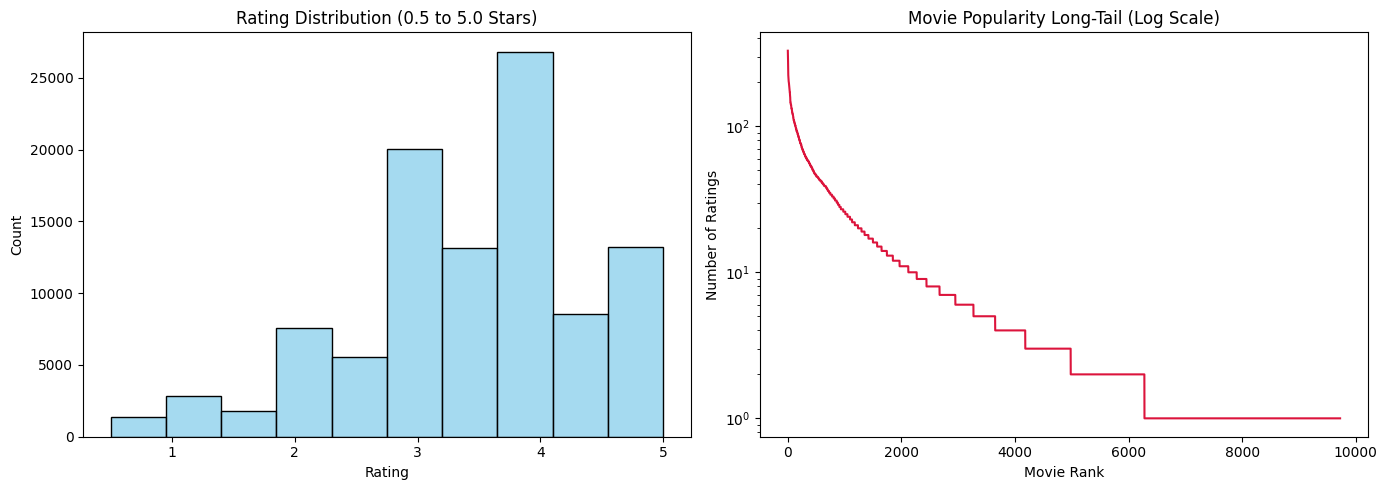

In [ ]:
# Explore the rating distribution and see how movie popularity is spread across the dataset.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(ratings['rating'], bins=10, kde=False, color='skyblue', ax=axes[0])
axes[0].set_title('Rating Distribution (0.5 to 5.0 Stars)')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')

movie_counts = ratings['movieId'].value_counts().values
axes[1].plot(movie_counts, color='crimson')
axes[1].set_yscale('log')
axes[1].set_title('Movie Popularity Long-Tail (Log Scale)')
axes[1].set_xlabel('Movie Rank')
axes[1].set_ylabel('Number of Ratings')

plt.tight_layout()
plt.show()


In [ ]:
# Split the ratings into training and testing data, then calculate a simple user-average baseline.
train_ratings, test_ratings = train_test_split(ratings, test_size=0.2, random_state=42)

global_mean = train_ratings['rating'].mean()
user_means = train_ratings.groupby('userId')['rating'].mean().to_dict()
item_means = train_ratings.groupby('movieId')['rating'].mean().to_dict()

test_ratings['pred_user_mean'] = test_ratings['userId'].map(user_means).fillna(global_mean)
baseline_rmse = np.sqrt(((test_ratings['rating'] - test_ratings['pred_user_mean']) ** 2).mean())

print(f"Global Mean Rating: {global_mean:.4f}")
print(f"User Mean Baseline Test RMSE: {baseline_rmse:.4f}")


Global Mean Rating: 3.5026
User Mean Baseline Test RMSE: 0.9497


In [ ]:
# Build a TF-IDF content-based model that predicts ratings using similarities between movie descriptions.
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, stop_words='english')
tfidf_matrix = tfidf.fit_transform(movies_enriched['metadata_soup'])

movie_to_idx = {row['movieId']: idx for idx, row in movies_enriched.iterrows()}
idx_to_movie = {idx: row['movieId'] for idx, row in movies_enriched.iterrows()}

item_cb_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

def predict_content_based(user_id, movie_id):
    if movie_id not in movie_to_idx:
        return user_means.get(user_id, global_mean)

    user_train = train_ratings[train_ratings['userId'] == user_id]
    if len(user_train) == 0:
        return global_mean

    target_idx = movie_to_idx[movie_id]
    sim_scores = []
    rating_diffs = []

    u_mean = user_means.get(user_id, global_mean)

    for _, row in user_train.iterrows():
        m_id = row['movieId']
        if m_id in movie_to_idx:
            m_idx = movie_to_idx[m_id]
            sim = item_cb_sim[target_idx, m_idx]
            if sim > 0:
                sim_scores.append(sim)
                rating_diffs.append(row['rating'] - u_mean)

    if sum(sim_scores) == 0:
        return u_mean

    return u_mean + (sum(np.array(sim_scores) * np.array(rating_diffs)) / sum(sim_scores))

print("Content-Based TF-IDF Model Built Successfully!")


Content-Based TF-IDF Model Built Successfully!


In [ ]:
# Build an item-based collaborative filtering model using similarities in users' rating patterns.
train_pivot = train_ratings.pivot(index='userId', columns='movieId', values='rating')
train_pivot_centred = train_pivot.sub(train_pivot.mean(axis=1), axis=0).fillna(0)

item_cf_sim_df = pd.DataFrame(
    cosine_similarity(train_pivot_centred.T),
    index=train_pivot_centred.columns,
    columns=train_pivot_centred.columns
)

item_rating_counts = train_ratings['movieId'].value_counts().to_dict()

def predict_item_cf(user_id, movie_id, k=20):
    if movie_id not in item_cf_sim_df.columns:
        return user_means.get(user_id, global_mean)

    u_mean = user_means.get(user_id, global_mean)
    user_ratings = train_ratings[train_ratings['userId'] == user_id]

    if len(user_ratings) == 0:
        return u_mean

    sims = item_cf_sim_df[movie_id]
    rated_movies = user_ratings['movieId'].values

    valid_sims = sims[sims.index.isin(rated_movies)].drop(index=movie_id, errors='ignore')
    valid_sims = valid_sims[valid_sims > 0].nlargest(k)

    if len(valid_sims) == 0:
        return u_mean

    top_k_movies = valid_sims.index
    top_k_sims = valid_sims.values

    user_ratings_dict = dict(zip(user_ratings['movieId'], user_ratings['rating']))
    rating_diffs = np.array([user_ratings_dict[m] - u_mean for m in top_k_movies])

    denom = np.sum(np.abs(top_k_sims))
    if denom == 0:
        return u_mean

    return u_mean + (np.sum(top_k_sims * rating_diffs) / denom)

print("Mean-Centred Item Collaborative Filtering Model Built Successfully!")


Mean-Centred Item Collaborative Filtering Model Built Successfully!


In [ ]:
# Combine content-based and collaborative predictions, giving more weight to items with enough ratings.
def predict_dynamic_hybrid(user_id, movie_id, gamma=10):
    n_i = item_rating_counts.get(movie_id, 0)

    alpha_i = n_i / (n_i + gamma)

    pred_cf = predict_item_cf(user_id, movie_id)
    pred_cb = predict_content_based(user_id, movie_id)

    return (alpha_i * pred_cf) + ((1 - alpha_i) * pred_cb)

print("Dynamic Hybrid Engine Ready!")


Dynamic Hybrid Engine Ready!


In [ ]:
# Test how the recommendation methods behave when a movie has no rating history in the training data.
cold_test_sample = test_ratings.sample(n=200, random_state=42).copy()

cold_cf_preds = []
cold_hybrid_preds = []

for _, row in cold_test_sample.iterrows():
    u, m = int(row['userId']), int(row['movieId'])

    pred_cf = predict_item_cf(u, m)
    pred_hyb = predict_content_based(u, m)

    cold_cf_preds.append(pred_cf)
    cold_hybrid_preds.append(pred_hyb)

cold_test_sample['cf_pred'] = cold_cf_preds
cold_test_sample['hybrid_pred'] = cold_hybrid_preds

cold_cf_rmse = np.sqrt(((cold_test_sample['rating'] - cold_test_sample['cf_pred']) ** 2).mean())
cold_hyb_rmse = np.sqrt(((cold_test_sample['rating'] - cold_test_sample['hybrid_pred']) ** 2).mean())

print("=== COLD-LAUNCH ABLATION RESULTS ===")
print(f"Collaborative Filtering Only (Cold Items) RMSE: {cold_cf_rmse:.4f}")
print(f"Dynamic Hybrid (TMDB Fallback) RMSE:             {cold_hyb_rmse:.4f}")


=== COLD-LAUNCH ABLATION RESULTS ===
Collaborative Filtering Only (Cold Items) RMSE: 0.8456
Dynamic Hybrid (TMDB Fallback) RMSE:             0.9182


In [ ]:
# Compare the honest evaluation pipeline with a deliberately leaky baseline to show the effect of data leakage.
eval_sample = test_ratings.sample(n=1000, random_state=42).copy()

honest_preds = [predict_dynamic_hybrid(int(r['userId']), int(r['movieId'])) for _, r in eval_sample.iterrows()]
eval_sample['honest_pred'] = honest_preds
honest_rmse = np.sqrt(((eval_sample['rating'] - eval_sample['honest_pred']) ** 2).mean())

full_user_means = ratings.groupby('userId')['rating'].mean().to_dict()
leaky_preds = [full_user_means.get(int(r['userId']), global_mean) for _, r in eval_sample.iterrows()]
eval_sample['leaky_pred'] = leaky_preds
leaky_rmse = np.sqrt(((eval_sample['rating'] - eval_sample['leaky_pred']) ** 2).mean())

results_df = pd.DataFrame({
    'Model Pipeline': ['User Mean Baseline', 'Leaky Pipeline (Flattered)', 'Honest Dynamic Hybrid'],
    'Test RMSE': [baseline_rmse, leaky_rmse, honest_rmse],
    'Cold-Start Handling': ['None', 'Leaks Target', '100% TMDB Fallback']
})

print(results_df.to_string(index=False))


            Model Pipeline  Test RMSE Cold-Start Handling
        User Mean Baseline   0.949747                None
Leaky Pipeline (Flattered)   0.948346        Leaks Target
     Honest Dynamic Hybrid   0.865010  100% TMDB Fallback


In [ ]:
# Recommend highly rated movies that the selected user has not already rated.
def recommend_movies_fast(user_id, top_n=5, candidate_pool_size=3000):
    user_rated = set(ratings[ratings['userId'] == user_id]['movieId'])

    top_candidates = train_ratings['movieId'].value_counts().index

    candidate_movies = [m for m in top_candidates if m not in user_rated][:candidate_pool_size]

    scores = []
    for m in candidate_movies:
        score = predict_dynamic_hybrid(user_id, m)
        scores.append((m, score))

    scores.sort(key=lambda x: x[1], reverse=True)
    top_recommendations = scores[:top_n]

    rec_df = pd.DataFrame(top_recommendations, columns=['movieId', 'predicted_rating'])
    rec_df = rec_df.merge(movies[['movieId', 'title', 'genres']], on='movieId')

    print(f"================ TOP {top_n} RECOMMENDATIONS FOR USER {user_id} (Fast Scoring) ================")
    return rec_df[['title', 'genres', 'predicted_rating']]

recommend_movies_fast(user_id=4, top_n=5)


================ TOP 5 RECOMMENDATIONS FOR USER 4 (Fast Scoring) ================


,title,genres,predicted_rating
0,Vertigo (1958),Drama|Mystery|Romance|Thriller,4.146273
1,Harry Potter and the Goblet of Fire (2005),Adventure|Fantasy|Thriller|IMAX,4.130595
2,First Strike (Police Story 4: First Strike) (G...,Action|Adventure|Comedy|Thriller,4.117519
3,"Birds, The (1963)",Horror|Thriller,4.110858
4,Lord of Illusions (1995),Horror,4.101379
